In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torchvision import datasets, transforms

In [11]:
# HYPERPARAMS
batch_size = 128
learning_rate = 1e-3
eval_iters = 100
estimate_loss_iters = 100

current_step = 0

In [12]:
transform = transforms.Compose([
    transforms.ToTensor(), # Converts image to PyTorch Tensor and scales to [0, 1]
    transforms.Normalize((0.5,), (0.5,)), # Shifts values to range [-1, 1] for stability
    transforms.Lambda(lambda x: torch.flatten(x))
])

# Train=True gets the 60,000 training images
train_set = datasets.MNIST(
    root='./data', 
    train=True, 
    download=False, 
    transform=transform
)

# Train=False gets the 10,000 test images (for checking accuracy later)
test_set = datasets.MNIST(
    root='./data', 
    train=False, 
    download=False, 
    transform=transform
)

In [13]:
# DEFINE GET BATCH FUNCTION
def get_batch(split, batch_size):
    """fetches a random batch of images to train on"""

    data = train_set if split == 'train' else test_set
    ix = np.random.randint(len(data), size=(batch_size,))

    x = np.vstack([data[i][0] for i in ix])
    y = np.array([data[i][1] for i in ix])
    return x, y

In [14]:
def estimate_loss():
    out = {}
    for split in ['train', 'val']:
        correct_counts = 0
        total_counts = 0
        out[split] = 0
        for k in range(estimate_loss_iters):
            X, Y = get_batch(split, batch_size)
            logits, loss, grad = m.forward(X, Y)
            out[split] += loss / estimate_loss_iters
            guesses = np.argmax(logits, axis=-1)
            correct_counts += (guesses == Y).sum().item()
            total_counts += Y.size
        out[f'{split}_acc'] = (correct_counts / total_counts) * 100
    return out

In [15]:
def cross_entropy(logits, targets):
    # Log-Sum-Exp trick for numerical stability
    max_logits = np.max(logits, axis=-1, keepdims=True)
    log_sum_exp = max_logits + np.log(np.sum(np.exp(logits - max_logits), axis=-1, keepdims=True))
    
    # Direct log-probability
    log_probs = logits - log_sum_exp
    
    # NLL Loss
    n_samples = logits.shape[0]
    loss = -np.sum(log_probs[np.arange(n_samples), targets]) / n_samples
    
    # Gradient calculation (this stays the same and is very stable)
    softmax_probs = np.exp(log_probs)
    target_array = np.zeros_like(logits)
    target_array[np.arange(n_samples), targets] = 1
    return loss, (softmax_probs - target_array) / n_samples

class AdamW:
    def __init__(self, params, betas=(0.9, 0.999), eps=1e-08, weight_decay=0.01):
        self.mt = np.zeros(params.shape)
        self.vt = np.zeros(params.shape)
        self.b1 = betas[0]
        self.b2 = betas[1]
        self.eps = eps
        self.wd = weight_decay
        self.t = 0

    def step(self, w, grad, L):
        self.t += 1
        w -= L * self.wd * w
        self.mt = self.b1 * self.mt + (1 - self.b1) * grad
        self.vt = self.b2 * self.vt + (1 - self.b2) * grad**2
        m_hat = self.mt / (1 - self.b1**self.t)
        v_hat = self.vt / (1 - self.b2**self.t)
        return w - L * m_hat / (np.sqrt(v_hat + self.eps))
        
class ReLU:
    def __init__(self):
        self.z = None

    def forward(self, x):
        self.z = x
        return np.maximum(0, x)

    def backward(self, grad):
        return grad * (self.z > 0)
        
class Linear:
    def __init__(self, in_feat, out_feat):
        self.w = np.random.normal(loc=0.0, scale=np.sqrt(2/in_feat), size=(in_feat, out_feat))
        self.b = np.zeros((1, out_feat))
        self.x = None
        self.dw = np.zeros((in_feat, out_feat))
        self.db = np.zeros((1, out_feat))
        self.woptim = AdamW(self.w)
        self.boptim = AdamW(self.b)

    def forward(self, x):
        self.x = x
        return (x @ self.w) + self.b

    def backward(self, grad):
        self.dw += self.x.T @ grad
        self.db += np.sum(grad, axis=0, keepdims=True)
        return grad @ self.w.T   # the gradients of the loss with respect to the input for this layer to be passed down

    def step(self, L):
        self.w = self.woptim.step(self.w, self.dw, L)
        self.b = self.boptim.step(self.b, self.d, L)

    def zero_grad(self):
        self.dw = np.zeros(self.w.shape)
        self.db = np.zeros(self.b.shape)
        
        
class Layer:
    def __init__(self, in_feat, out_feat):
        self.linear = Linear(in_feat, out_feat)
        self.relu = ReLU()

    def forward(self, x):
        return self.relu.forward(self.linear.forward(x))

    def backward(self, grad):
        return self.linear.backward(self.relu.backward(grad))

    def step(self, L):
        self.linear.step(L)

    def zero_grad(self):
        self.linear.zero_grad()

class NN:
    def __init__(self, layers):
        self.layers = [Layer(in_feat, out_feat) for in_feat, out_feat in layers]
        self.lm_head = Linear(layers[-1][1], 10)
        
    def forward(self, x, targets=None):
        x = np.array(x)
        for layer in self.layers:
            x = layer.forward(x)
        logits = self.lm_head.forward(x)

        if targets is None:
            return logits
        else:
            loss, grad = cross_entropy(logits, np.array(targets))
            return logits, loss, grad

    def backward(self, grad):
        grad = self.lm_head.backward(grad)
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def step(self, L):
        self.lm_head.step(L)
        for layer in self.layers:
            layer.step(L)

    def zero_grad(self):
        self.lm_head.zero_grad()
        for layer in self.layers:
            layer.zero_grad()

    def predict(self, x):
        logits = self.forward(x)
        return np.argmax(logits, axis=-1)

In [16]:
m = NN([[784, 256]])

In [17]:
# How Many total steps do you want to train to?
max_iters = 2000

In [18]:
losses = estimate_loss()    # estimate a base loss before training session
print(f"Step: {current_step:04d}, Train Loss: {losses['train']:.3f}, Val Loss: {losses['val']:.3f}")
print(f"            Train Accu: {losses['train_acc']:.2f}%,Val Accu: {losses['val_acc']:.2f}%")

for step in range(current_step+1, max_iters + 1):
    m.zero_grad()
    xb, yb= get_batch('train', batch_size)
    logits, loss, grad = m.forward(xb, yb)
    m.backward(grad)
    
    m.step(learning_rate)
    current_step = step
    if step % eval_iters == 0:
        
        print()
        losses = estimate_loss()

        print(f"Step: {step:04d}, Train Loss: {losses['train']:.3f}, Val Loss: {losses['val']:.3f}")
        print(f"            Train Accu: {losses['train_acc']:.2f}%,Val Accu: {losses['val_acc']:.2f}%")

Step: 0000, Train Loss: 3.282, Val Loss: 3.313
            Train Accu: 10.02%,Val Accu: 9.58%

Step: 0100, Train Loss: 0.372, Val Loss: 0.350
            Train Accu: 89.09%,Val Accu: 89.60%

Step: 0200, Train Loss: 0.281, Val Loss: 0.276
            Train Accu: 91.48%,Val Accu: 91.89%

Step: 0300, Train Loss: 0.241, Val Loss: 0.223
            Train Accu: 92.95%,Val Accu: 93.30%

Step: 0400, Train Loss: 0.202, Val Loss: 0.196
            Train Accu: 93.88%,Val Accu: 93.73%

Step: 0500, Train Loss: 0.165, Val Loss: 0.181
            Train Accu: 95.21%,Val Accu: 94.23%

Step: 0600, Train Loss: 0.163, Val Loss: 0.175
            Train Accu: 95.29%,Val Accu: 94.81%

Step: 0700, Train Loss: 0.156, Val Loss: 0.173
            Train Accu: 95.52%,Val Accu: 95.12%

Step: 0800, Train Loss: 0.135, Val Loss: 0.138
            Train Accu: 95.95%,Val Accu: 95.62%

Step: 0900, Train Loss: 0.141, Val Loss: 0.151
            Train Accu: 95.60%,Val Accu: 95.52%

Step: 1000, Train Loss: 0.116, Val Loss: 

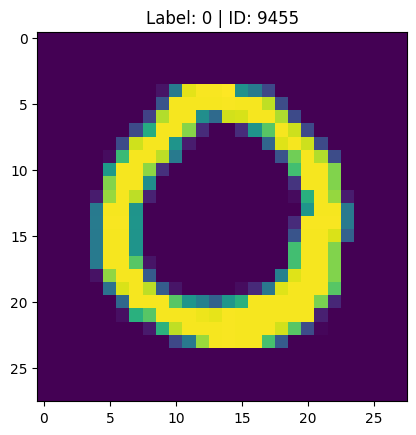

Guess: [0]


In [90]:
# Generate Guess
image_id = np.random.randint(0, 10000)
flat_vector, label = test_set[image_id]

# Reshape it for plotting
# Matplotlib expects [Height, Width]
image_to_show = flat_vector.view(28, 28)

# Plot it
plt.imshow(image_to_show)
plt.title(f"Label: {label} | ID: {image_id}")
plt.show()

# Print Guess
print(f"Guess: {m.predict(flat_vector)}")